In [ ]:
import pandas as pd
import numpy as np


# Data management

In [4]:
# importer les phenologies brutes
s2ps2 = pd.read_csv("../data/old/pheno_RI_s2ps2.csv")
s2 = pd.read_csv("../data/old/pheno_RI_s2.csv")

# supprimer colonne inutile
s2ps2 = s2ps2.drop(columns=["Unnamed: 0"])
s2 = s2.drop(columns=["Unnamed: 0"])

# index
s2ps2 = s2ps2.rename(columns={"doy.Beck.flag": "flag"})
s2 = s2.rename(columns={"doy.Beck.flag": "flag"})



In [6]:
doy_cols = [c for c in s2ps2.columns if c.startswith("doy.Beck.")]

keep_cols = ["flag"] + doy_cols # colonnes à garder

s2ps2_clean = s2ps2[keep_cols].copy()
s2_clean = s2[keep_cols].copy()

In [7]:
# noms des colonnes propres

s2ps2_clean.columns = [
    c.replace("doy.Beck.", "")
    for c in s2ps2_clean.columns
]

s2_clean.columns = [
    c.replace("doy.Beck.", "")
    for c in s2_clean.columns
]

In [10]:
df = s2ps2_clean.merge(
    s2_clean,
    on="flag",
    suffixes=("_s2ps2", "_s2")
)

In [12]:
print(df.columns)

Index(['flag', 'origin_s2ps2', 'TRS2.sos_s2ps2', 'TRS2.eos_s2ps2',
       'TRS5.sos_s2ps2', 'TRS5.eos_s2ps2', 'TRS6.sos_s2ps2', 'TRS6.eos_s2ps2',
       'DER.sos_s2ps2', 'DER.pos_s2ps2', 'DER.eos_s2ps2', 'UD_s2ps2',
       'SD_s2ps2', 'DD_s2ps2', 'RD_s2ps2', 'Greenup_s2ps2', 'Maturity_s2ps2',
       'Senescence_s2ps2', 'Dormancy_s2ps2', 'origin_s2', 'TRS2.sos_s2',
       'TRS2.eos_s2', 'TRS5.sos_s2', 'TRS5.eos_s2', 'TRS6.sos_s2',
       'TRS6.eos_s2', 'DER.sos_s2', 'DER.pos_s2', 'DER.eos_s2', 'UD_s2',
       'SD_s2', 'DD_s2', 'RD_s2', 'Greenup_s2', 'Maturity_s2', 'Senescence_s2',
       'Dormancy_s2'],
      dtype='object')


# Compute the delta in every phenological metric

In [13]:
# recup les colonnes d'intérêt
metrics = [
    c for c in s2ps2_clean.columns
    if c not in ["flag", "origin"]
]

In [15]:
# calcul du delta + ajout d'un préfixe
for m in metrics:
    df[f"d_{m}"] = (
        df[f"{m}_s2ps2"]
        - df[f"{m}_s2"]
    )

In [16]:
#summary metrics (en jours) of the deltas sur toutes les années

delta_cols = [c for c in df.columns if c.startswith("d_")]

summary = pd.DataFrame({
    "bias": df[delta_cols].mean(),
    "sd": df[delta_cols].std(),
    "mae": df[delta_cols].abs().mean(),
    "max_abs": df[delta_cols].abs().max()
})

print(summary.round(2))

               bias     sd    mae  max_abs
d_TRS2.sos   -21.33   8.94  21.33     37.0
d_TRS2.eos    31.89  12.30  31.89     50.0
d_TRS5.sos   -14.44   8.65  14.44     33.0
d_TRS5.eos    21.78  14.64  21.78     44.0
d_TRS6.sos   -11.89   8.87  11.89     32.0
d_TRS6.eos    18.56  17.02  18.56     47.0
d_DER.sos    -14.67   8.85  14.67     33.0
d_DER.pos     -3.67  27.02  22.33     46.0
d_DER.eos     23.33  14.83  23.33     47.0
d_UD         -24.67  10.90  24.67     47.0
d_SD          -4.22  12.62   8.22     33.0
d_DD           8.11  25.33  21.44     51.0
d_RD          38.33  13.17  38.33     53.0
d_Greenup    -27.67  12.90  27.67     54.0
d_Maturity    -7.11  13.98  11.11     33.0
d_Senescence -11.00  21.18  21.40     26.0
d_Dormancy    44.25  10.01  44.25     56.0


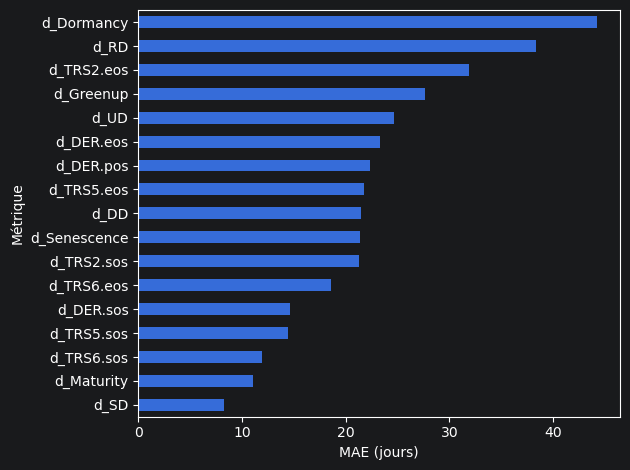

In [17]:
import matplotlib.pyplot as plt

summary["mae"].sort_values().plot.barh()

plt.xlabel("MAE (jours)")
plt.ylabel("Métrique")
plt.tight_layout()
plt.show()

In [18]:
# Biais ?
metrics = ["d_DER.sos", "d_DER.pos", "d_DER.eos"]

bias = df[metrics].mean()
print(bias)

# modis avance le debut de saison
# modis retarde la fin de saison
# pas trop d'effet sur le pic

d_DER.sos   -14.666667
d_DER.pos    -3.666667
d_DER.eos    23.333333
dtype: float64


In [19]:
# mean absolute error
mae = df[metrics].abs().mean()
print(mae)

d_DER.sos    14.666667
d_DER.pos    22.333333
d_DER.eos    23.333333
dtype: float64


## correlations

In [22]:
from scipy.stats import pearsonr

r_sos, p_sos = pearsonr(df["DER.sos_s2ps2"], df["DER.sos_s2"])
r_eos, p_eos = pearsonr(df["DER.eos_s2ps2"], df["DER.eos_s2"])

print(r_sos, r_eos)
print(p_sos, p_eos)


# debuts de saisons s2 vs s2ps2 pas correlés

0.64978197458776 0.19497190721386715
0.05818569566657152 0.615174673694339


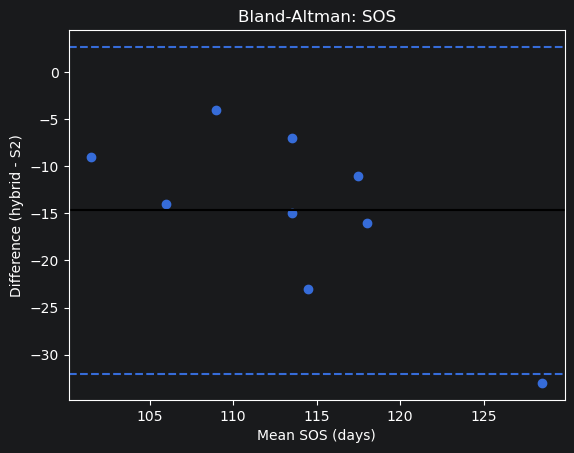

In [24]:
import matplotlib.pyplot as plt

x = (df["DER.sos_s2ps2"] + df["DER.sos_s2"]) / 2
y = df["d_DER.sos"]

mean_bias = y.mean()
sd = y.std()

plt.scatter(x, y)

plt.axhline(mean_bias, color="black")
plt.axhline(mean_bias + 1.96*sd, linestyle="--")
plt.axhline(mean_bias - 1.96*sd, linestyle="--")

plt.xlabel("Mean SOS (days)")
plt.ylabel("Difference (hybrid - S2)")
plt.title("Bland-Altman: SOS")
plt.show()